In [1]:
%pip -q install rpy2
%load_ext rpy2.ipython
print("R magic is ready. Run the R cells below.")

R magic is ready. Run the R cells below.


# Week 12 — Graphics and R Programming Examples


## 1. Component / subdivided bar plot

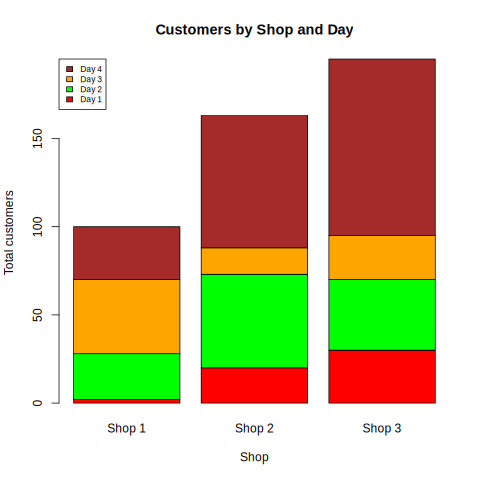

In [2]:
%%R
customers <- matrix(
  c(2, 20, 30,
    26, 53, 40,
    42, 15, 25,
    30, 75, 100),
  nrow = 4, byrow = TRUE
)
colnames(customers) <- c("Shop 1", "Shop 2", "Shop 3")
rownames(customers) <- c("Day 1", "Day 2", "Day 3", "Day 4")
customers

# Matrix columns become stacked bars in base R.
barplot(customers, main = "Customers by Shop and Day",
        xlab = "Shop", ylab = "Total customers",
        col = c("red", "green", "orange", "brown"),
        legend.text = rownames(customers), args.legend = list(x = "topleft", cex = 0.7))

## 2. Pie diagram and combined graphics

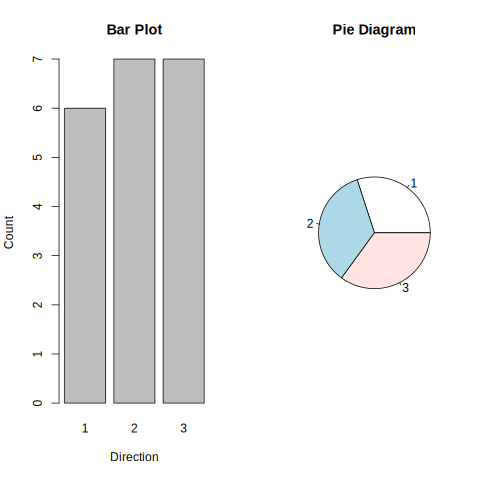

In [3]:
%%R
gender <- c(1, 2, 1, 2, 1, 1, 1, 2, 1, 1)
gender_counts <- table(gender)
pie(gender_counts, labels = paste(names(gender_counts), gender_counts),
    col = c("skyblue", "pink"), main = "Category Proportions")

direction <- c(1,1,2,1,2,3,2,2,3,3,3,1,2,3,2,2,3,1,1,3)
par(mfrow = c(1, 2))
barplot(table(direction), main = "Bar Plot", xlab = "Direction", ylab = "Count")
pie(table(direction), main = "Pie Diagram")
par(mfrow = c(1, 1))

## 3. Histogram for continuous data

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  56.00   72.00   79.00   77.88   85.00   97.00 


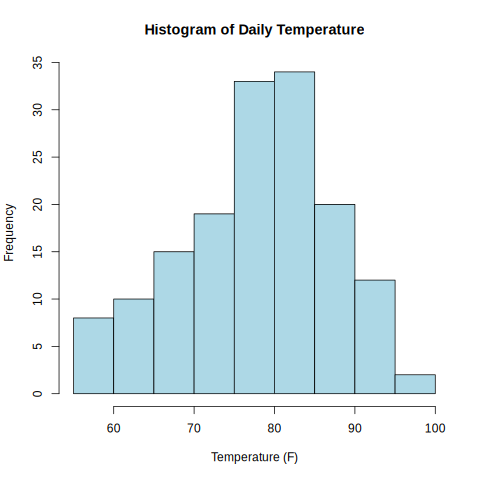

In [4]:
%%R
data(airquality)
hist(airquality$Temp,
     main = "Histogram of Daily Temperature",
     xlab = "Temperature (F)",
     ylab = "Frequency",
     col = "lightblue",
     breaks = 10)

# Histogram represents the distribution of continuous measurements.
summary(airquality$Temp)

## 4. Bivariate scatter plots and relationship types

[1] 0.9679961


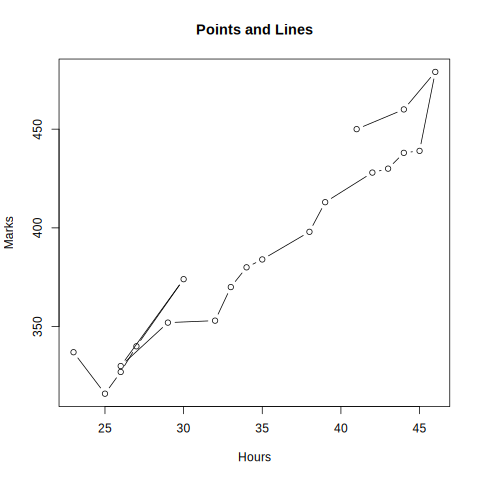

In [5]:
%%R
marks <- c(337,316,327,340,374,330,352,353,370,380,
           384,398,413,428,430,438,439,479,460,450)
hours <- c(23,25,26,27,30,26,29,32,33,34,
           35,38,39,42,43,44,45,46,44,41)

plot(hours, marks, main = "Study Hours and Marks",
     xlab = "Study hours", ylab = "Marks",
     pch = 19, col = "blue")
abline(lm(marks ~ hours), col = "red", lwd = 2)

# Scatter plot types described in the notes: p, l, b, c, o, s, h
plot(hours, marks, type = "b", main = "Points and Lines",
     xlab = "Hours", ylab = "Marks")
cor(hours, marks)

## 5. Three-dimensional scatter plot (base R)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/scatterplot3d_0.3-45.tar.gz'
Content type 'application/x-gzip' length 484624 bytes (473 KB)
downloaded 473 KB


The downloaded source packages are in
	‘/tmp/Rtmps3SKzN/downloaded_packages’


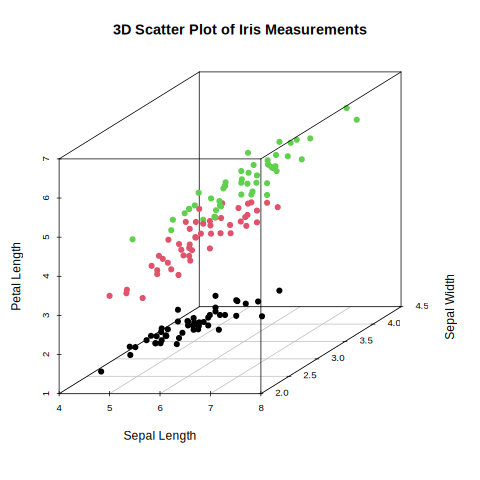

In [6]:
%%R
# Use a 3D scatter plot via the built-in graphics package 'scatterplot3d'.
# Install it if necessary; package installation requires internet access.
if (!requireNamespace("scatterplot3d", quietly = TRUE)) {
  install.packages("scatterplot3d", repos = "https://cloud.r-project.org")
}
if (requireNamespace("scatterplot3d", quietly = TRUE)) {
  scatterplot3d::scatterplot3d(iris$Sepal.Length, iris$Sepal.Width, iris$Petal.Length,
       color = as.numeric(iris$Species),
       pch = 19, main = "3D Scatter Plot of Iris Measurements",
       xlab = "Sepal Length", ylab = "Sepal Width", zlab = "Petal Length")
}

## 6. Write functions and use loops / vectorization

In [7]:
%%R
# Example function: calculate two ratios from input vectors.
example1 <- function(x, y) {
  if (!is.numeric(x) || !is.numeric(y)) stop("x and y must be numeric.")
  if (length(x) == 0 || length(y) == 0) stop("Inputs cannot be empty.")
  if (sum(y^2) == 0) stop("sum(y^2) must not be zero.")
  g <- sum(x^2) / sum(y^2)
  h <- sum(x) / sum(y)
  c(g = g, h = h)
}
x <- c(10, 20, 30)
y <- c(1, 2, 3)
example1(x, y)

# Example: compare a loop with a vectorized expression.
values <- 1:10
squared_loop <- numeric(length(values))
for (i in seq_along(values)) {
  squared_loop[i] <- values[i]^2
}
squared_vectorized <- values^2
data.frame(value = values, loop_square = squared_loop,
           vectorized_square = squared_vectorized)

# Vectorization is generally concise and often faster than explicit loops.

   value loop_square vectorized_square
1      1           1                 1
2      2           4                 4
3      3           9                 9
4      4          16                16
5      5          25                25
6      6          36                36
7      7          49                49
8      8          64                64
9      9          81                81
10    10         100               100
